#Phase I: Long-Sequence LCS Experiments (1-20 Characters)

PHASE I: LCS EXPERIMENTAL RESULTS


,Group,Experiment,X,Y,m,n,Total Length,LCS Length,DP Comparisons,Recursive Comparisons,Recursive Calls,Recursive Depth,DP Cells,Imbalance,DP Time (ms),Recursive Time (ms),Recursive Status
0,Equal,1,d,d,1,1,2,1,1,1.0,2.0,2.0,4,0.000,0.00675,0.00773,Completed
1,Equal,2,ca,bc,2,2,4,1,4,4.0,8.0,4.0,9,0.000,0.00491,0.00798,Completed
2,Equal,3,cca,aba,3,3,6,1,9,6.0,12.0,5.0,16,0.000,0.00597,0.00804,Completed
3,Equal,4,acca,dacb,4,4,8,2,16,23.0,39.0,7.0,25,0.000,0.00952,0.01962,Completed
4,Equal,5,abadd,acabd,5,5,10,3,25,28.0,44.0,9.0,36,0.000,0.01100,0.02102,Completed
5,Equal,6,adbbcb,abacda,6,6,12,3,36,322.0,514.0,12.0,49,0.000,0.01526,0.27734,Completed
6,Equal,7,aabcdcad,bbdaacaa,8,8,16,4,64,716.0,1295.0,15.0,81,0.000,0.03337,0.67377,Completed
7,Equal,8,dadbdadccb,cbbbadaddd,10,10,20,5,100,14301.0,27550.0,20.0,121,0.000,0.04468,33.70824,Completed
8,Equal,9,bdddacddbbabaaa,cacdcdcdbacdddc,15,15,30,7,225,NaN,NaN,NaN,256,0.000,0.08845,NaN,Time limit
9,Equal,10,bbcabddbbcadcdccbdcd,babdcabbdabdcacdbdcd,20,20,40,15,400,191345.0,294133.0,35.0,441,0.000,0.14527,292.43291,Completed


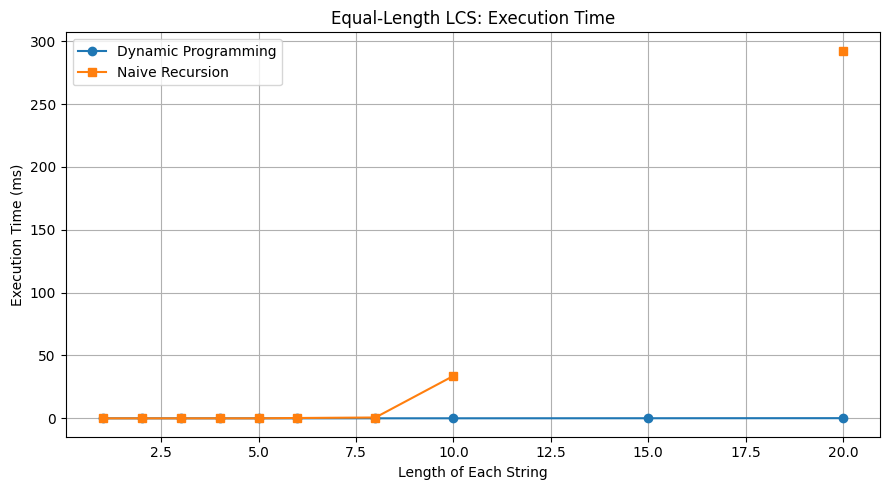

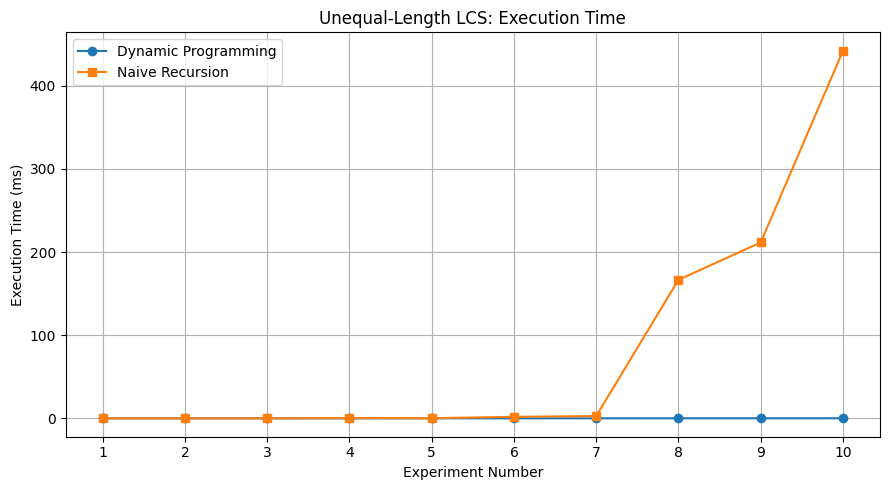

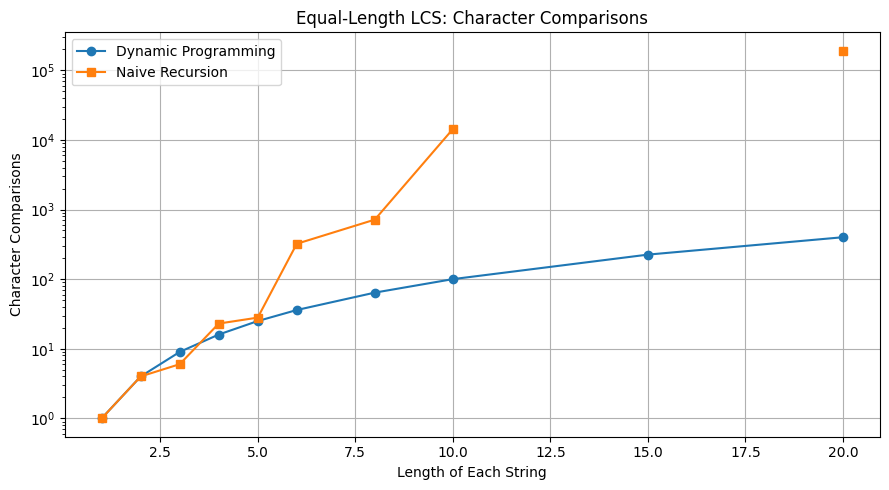

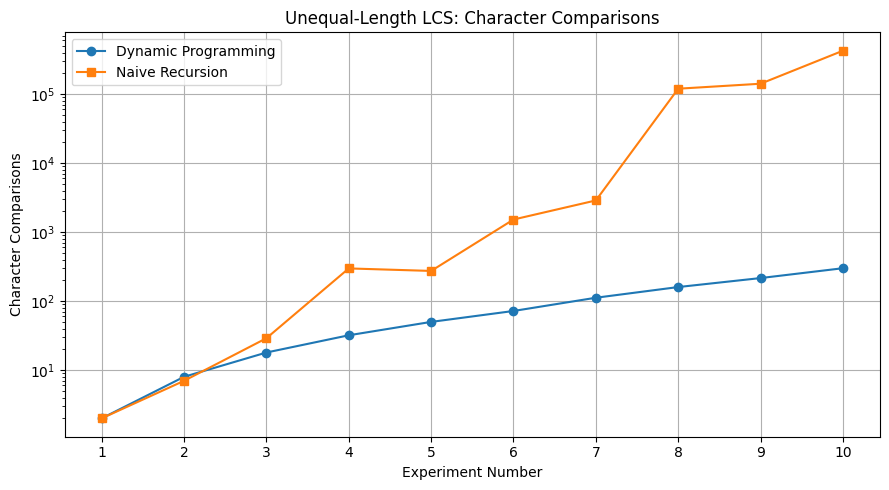

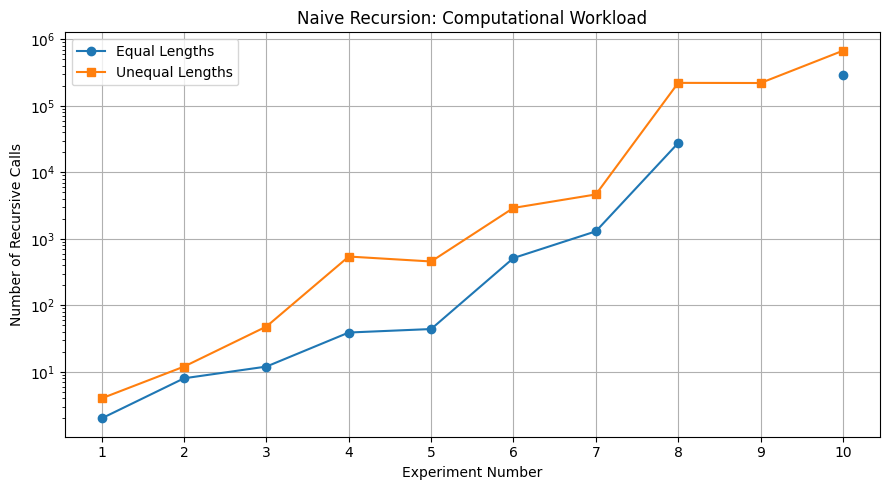

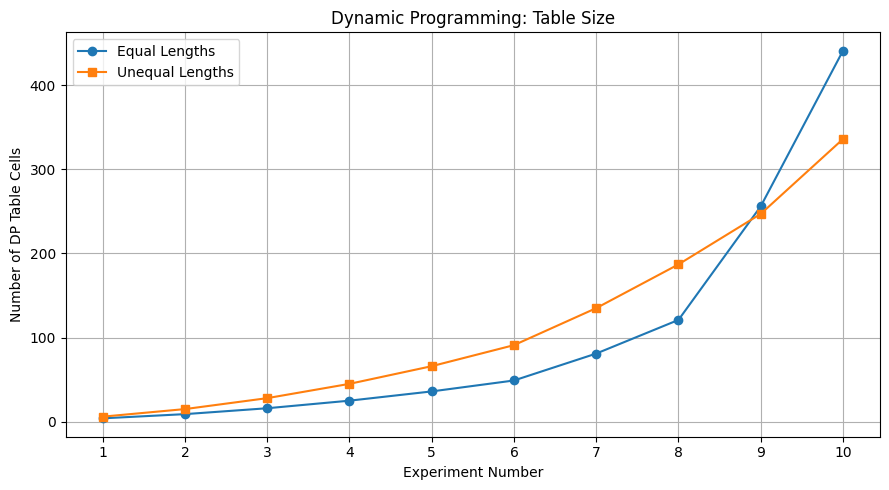

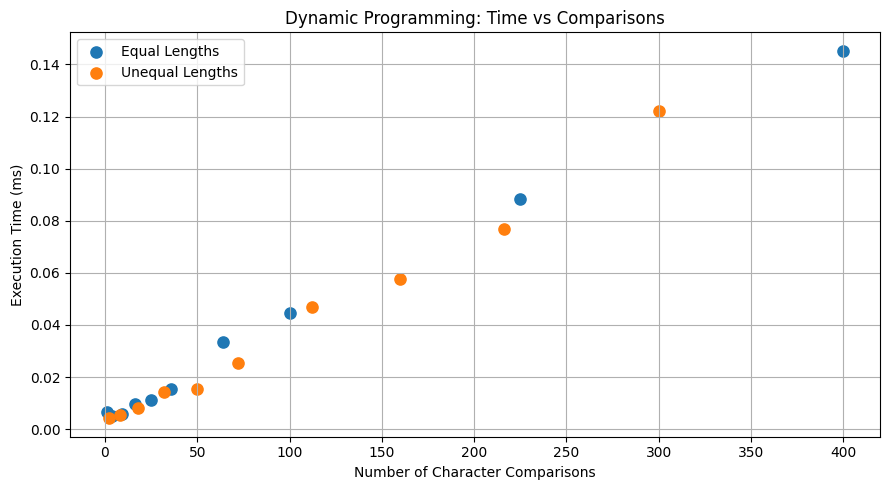


PHASE I SUMMARY


,Mean_DP_Time,Mean_Recursive_Time,Mean_DP_Comparisons,Mean_Recursive_Comparisons,Mean_Recursive_Calls,Mean_DP_Cells
Group,,,,,,
Equal,0.03652,36.35074,88.0,22971.77778,35955.22222,103.8
Unequal,0.03757,82.52162,97.0,69322.90000,112070.00000,115.6



RECURSIVE EXECUTION STATUS


Recursive Status,Completed,Time limit
Group,,
Equal,9,1
Unequal,10,0



Phase I completed.
Results saved as LCS_Phase1_Results.csv


In [ ]:

import random
import time
import statistics
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# 1. EXPERIMENT SETTINGS
# ==================================================

rng = random.Random(528)
alphabet = "abcd"
time_limit = 1.0       # Seconds allowed per recursive run
repetitions = 3
results = []


# ==================================================
# 2. NAIVE RECURSIVE LCS
# ==================================================

def recursive_lcs(X, Y):
    calls = 0
    comparisons = 0
    max_depth = 0
    deadline = time.perf_counter() + time_limit

    def solve(m, n, depth):
        nonlocal calls, comparisons, max_depth

        calls += 1
        max_depth = max(max_depth, depth)

        # Stop excessively long recursive computations
        if calls % 1024 == 0:
            if time.perf_counter() > deadline:
                raise TimeoutError

        if m == 0 or n == 0:
            return 0

        comparisons += 1

        if X[m - 1] == Y[n - 1]:
            return 1 + solve(m - 1, n - 1, depth + 1)

        return max(
            solve(m - 1, n, depth + 1),
            solve(m, n - 1, depth + 1)
        )

    length = solve(len(X), len(Y), 1)

    return length, calls, comparisons, max_depth


# ==================================================
# 3. BOTTOM-UP DYNAMIC PROGRAMMING LCS
# ==================================================

def dynamic_lcs(X, Y):
    m = len(X)
    n = len(Y)

    dp = [[0] * (n + 1) for _ in range(m + 1)]
    comparisons = 0

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            comparisons += 1

            if X[i - 1] == Y[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(
                    dp[i - 1][j],
                    dp[i][j - 1]
                )

    return dp[m][n], comparisons


# ==================================================
# 4. GENERATE THE INPUT STRINGS
# ==================================================

def make_string(length):
    return "".join(rng.choices(alphabet, k=length))

# 10 equal-length pairs
equal_pairs = [
    (1, 1), (2, 2), (3, 3), (4, 4),
    (5, 5), (6, 6), (8, 8),
    (10, 10), (15, 15), (20, 20)
]

# 10 unequal-length pairs
unequal_pairs = [
    (1, 2), (2, 4), (3, 6), (4, 8),
    (5, 10), (6, 12), (8, 14),
    (10, 16), (12, 18), (15, 20)
]


# ==================================================
# 5. RUN THE 20 EXPERIMENTS
# ==================================================

for group, pairs in [
    ("Equal", equal_pairs),
    ("Unequal", unequal_pairs)
]:

    for experiment, (m, n) in enumerate(pairs, 1):

        X = make_string(m)
        Y = make_string(n)

        # ------------------------------------------
        # Dynamic Programming
        # ------------------------------------------

        dp_times = []

        for _ in range(repetitions):
            start = time.perf_counter_ns()

            dp_length, dp_comparisons = dynamic_lcs(X, Y)

            elapsed_ms = (
                time.perf_counter_ns() - start
            ) / 1_000_000

            dp_times.append(elapsed_ms)

        dp_time = statistics.median(dp_times)

        # ------------------------------------------
        # Naive Recursion
        # ------------------------------------------

        rec_times = []
        rec_calls = []
        rec_comparisons = []
        rec_depths = []
        status = "Completed"

        for _ in range(repetitions):
            start = time.perf_counter_ns()

            try:
                rec_length, calls, comparisons, depth = (
                    recursive_lcs(X, Y)
                )

                elapsed_ms = (
                    time.perf_counter_ns() - start
                ) / 1_000_000

                assert rec_length == dp_length

                rec_times.append(elapsed_ms)
                rec_calls.append(calls)
                rec_comparisons.append(comparisons)
                rec_depths.append(depth)

            except TimeoutError:
                status = "Time limit"
                break

        if status == "Completed":
            rec_time = statistics.median(rec_times)
            calls = rec_calls[0]
            rec_comp = rec_comparisons[0]
            depth = rec_depths[0]
        else:
            rec_time = float("nan")
            calls = float("nan")
            rec_comp = float("nan")
            depth = float("nan")

        # ------------------------------------------
        # Store Results
        # ------------------------------------------

        results.append({
            "Group": group,
            "Experiment": experiment,
            "X": X,
            "Y": Y,
            "m": m,
            "n": n,
            "Total Length": m + n,
            "LCS Length": dp_length,
            "DP Comparisons": dp_comparisons,
            "Recursive Comparisons": rec_comp,
            "Recursive Calls": calls,
            "Recursive Depth": depth,
            "DP Cells": (m + 1) * (n + 1),
            "Imbalance": abs(m - n) / (m + n),
            "DP Time (ms)": dp_time,
            "Recursive Time (ms)": rec_time,
            "Recursive Status": status
        })


# ==================================================
# 6. DISPLAY EXPERIMENTAL RESULTS
# ==================================================

df = pd.DataFrame(results)

print("PHASE I: LCS EXPERIMENTAL RESULTS")
print("=" * 70)

display(df.round({
    "Imbalance": 3,
    "DP Time (ms)": 5,
    "Recursive Time (ms)": 5
}))

# Save all results
df.to_csv("LCS_Phase1_Results.csv", index=False)


# ==================================================
# 7. PREPARE DATA FOR VISUALIZATION
# ==================================================

equal = df[df["Group"] == "Equal"]
unequal = df[df["Group"] == "Unequal"]


# ==================================================
# GRAPH 1: EQUAL-LENGTH EXECUTION TIME
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["m"],
    equal["DP Time (ms)"],
    marker="o",
    label="Dynamic Programming"
)

plt.plot(
    equal["m"],
    equal["Recursive Time (ms)"],
    marker="s",
    label="Naive Recursion"
)

plt.xlabel("Length of Each String")
plt.ylabel("Execution Time (ms)")
plt.title("Equal-Length LCS: Execution Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 2: UNEQUAL-LENGTH EXECUTION TIME
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    unequal["Experiment"],
    unequal["DP Time (ms)"],
    marker="o",
    label="Dynamic Programming"
)

plt.plot(
    unequal["Experiment"],
    unequal["Recursive Time (ms)"],
    marker="s",
    label="Naive Recursion"
)

plt.xlabel("Experiment Number")
plt.ylabel("Execution Time (ms)")
plt.title("Unequal-Length LCS: Execution Time")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 3: EQUAL-LENGTH CHARACTER COMPARISONS
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["m"],
    equal["DP Comparisons"],
    marker="o",
    label="Dynamic Programming"
)

plt.plot(
    equal["m"],
    equal["Recursive Comparisons"],
    marker="s",
    label="Naive Recursion"
)

plt.xlabel("Length of Each String")
plt.ylabel("Character Comparisons")
plt.title("Equal-Length LCS: Character Comparisons")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 4: UNEQUAL-LENGTH CHARACTER COMPARISONS
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    unequal["Experiment"],
    unequal["DP Comparisons"],
    marker="o",
    label="Dynamic Programming"
)

plt.plot(
    unequal["Experiment"],
    unequal["Recursive Comparisons"],
    marker="s",
    label="Naive Recursion"
)

plt.xlabel("Experiment Number")
plt.ylabel("Character Comparisons")
plt.title("Unequal-Length LCS: Character Comparisons")
plt.xticks(range(1, 11))
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 5: RECURSIVE CALLS
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["Experiment"],
    equal["Recursive Calls"],
    marker="o",
    label="Equal Lengths"
)

plt.plot(
    unequal["Experiment"],
    unequal["Recursive Calls"],
    marker="s",
    label="Unequal Lengths"
)

plt.xlabel("Experiment Number")
plt.ylabel("Number of Recursive Calls")
plt.title("Naive Recursion: Computational Workload")
plt.xticks(range(1, 11))
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 6: DP TABLE SIZE
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["Experiment"],
    equal["DP Cells"],
    marker="o",
    label="Equal Lengths"
)

plt.plot(
    unequal["Experiment"],
    unequal["DP Cells"],
    marker="s",
    label="Unequal Lengths"
)

plt.xlabel("Experiment Number")
plt.ylabel("Number of DP Table Cells")
plt.title("Dynamic Programming: Table Size")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 7: DP EXECUTION TIME VS COMPARISONS
# ==================================================

plt.figure(figsize=(9, 5))

plt.scatter(
    equal["DP Comparisons"],
    equal["DP Time (ms)"],
    label="Equal Lengths",
    s=65
)

plt.scatter(
    unequal["DP Comparisons"],
    unequal["DP Time (ms)"],
    label="Unequal Lengths",
    s=65
)

plt.xlabel("Number of Character Comparisons")
plt.ylabel("Execution Time (ms)")
plt.title("Dynamic Programming: Time vs Comparisons")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# 8. SUMMARY STATISTICS
# ==================================================

print("\nPHASE I SUMMARY")

summary = df.groupby("Group").agg(
    Mean_DP_Time=("DP Time (ms)", "mean"),
    Mean_Recursive_Time=("Recursive Time (ms)", "mean"),
    Mean_DP_Comparisons=("DP Comparisons", "mean"),
    Mean_Recursive_Comparisons=(
        "Recursive Comparisons", "mean"
    ),
    Mean_Recursive_Calls=("Recursive Calls", "mean"),
    Mean_DP_Cells=("DP Cells", "mean")
)

display(summary.round(5))

print("\nRECURSIVE EXECUTION STATUS")
display(pd.crosstab(
    df["Group"],
    df["Recursive Status"]
))

print("\nPhase I completed.")
print("Results saved as LCS_Phase1_Results.csv")


#Phase II: Long-Sequence LCS Experiments (25–500 Characters)

PHASE II: LCS EXPERIMENTAL RESULTS


,Group,Experiment,m,n,Total Length,LCS Length,Comparisons,DP Cells,Imbalance,Time (ms)
0,Equal,1,25,25,50,14,625,676,0.000,0.12705
1,Equal,2,50,50,100,31,2500,2601,0.000,0.49546
2,Equal,3,75,75,150,45,5625,5776,0.000,1.34181
3,Equal,4,100,100,200,61,10000,10201,0.000,2.12514
4,Equal,5,150,150,300,96,22500,22801,0.000,4.89379
5,Equal,6,200,200,400,131,40000,40401,0.000,8.65140
6,Equal,7,250,250,500,163,62500,63001,0.000,12.87654
7,Equal,8,300,300,600,192,90000,90601,0.000,19.05818
8,Equal,9,400,400,800,253,160000,160801,0.000,37.23910
9,Equal,10,500,500,1000,323,250000,251001,0.000,59.25025


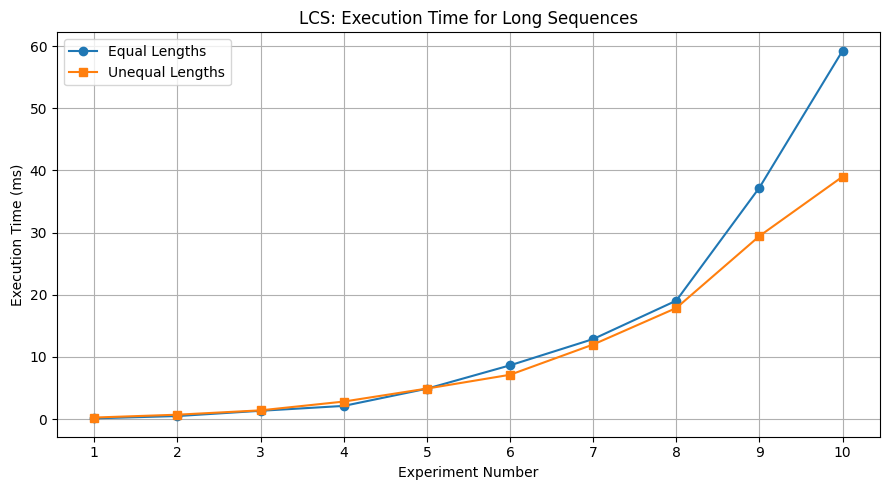

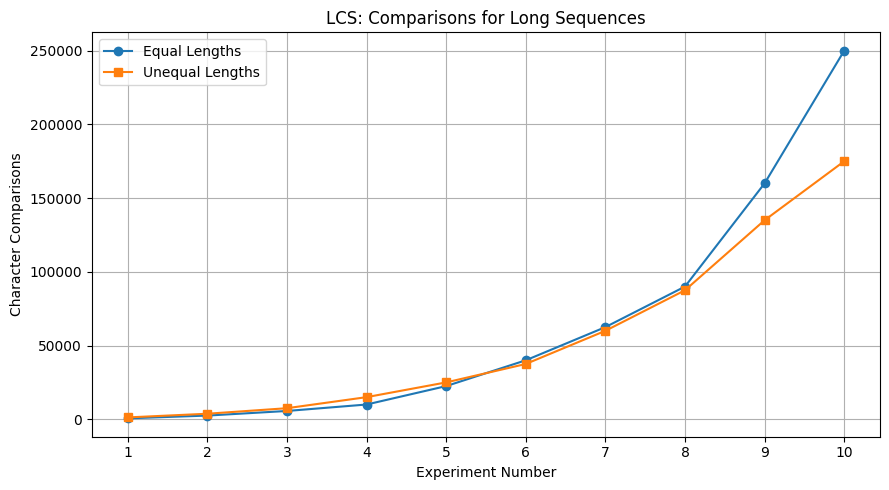

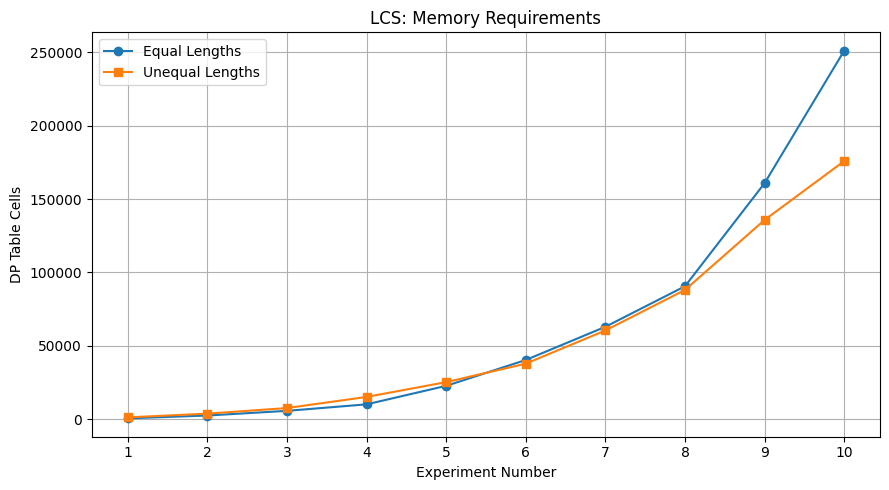

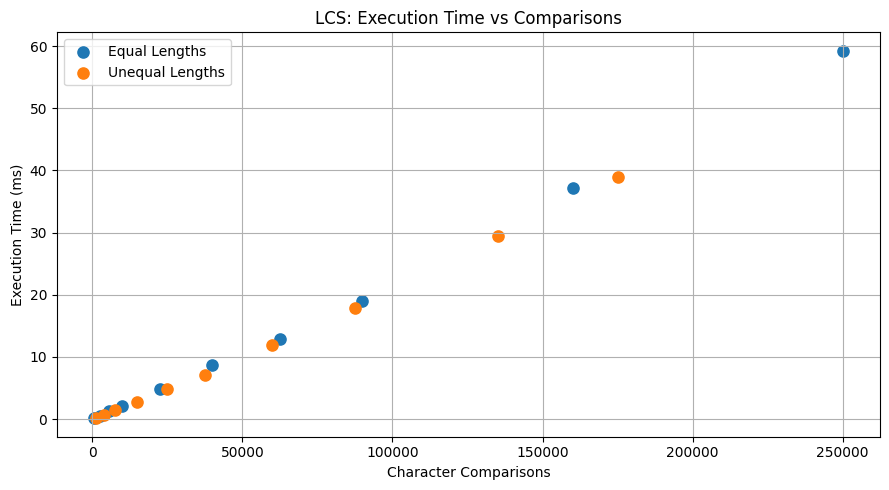

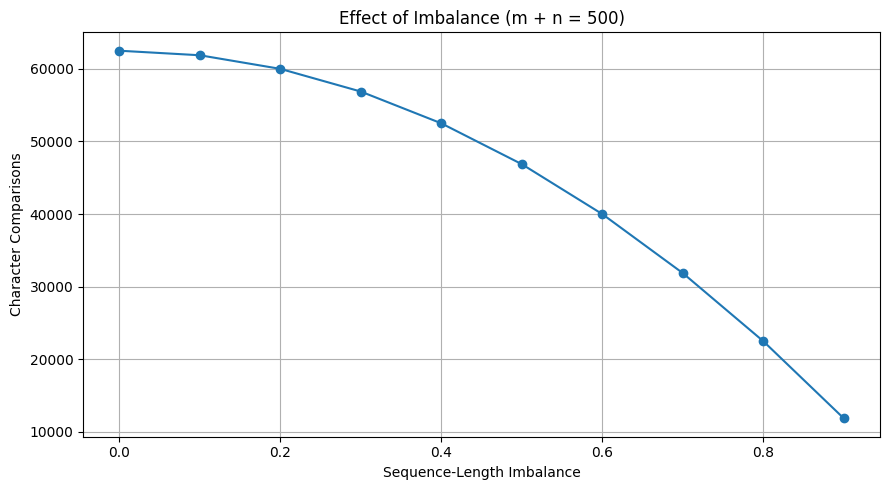

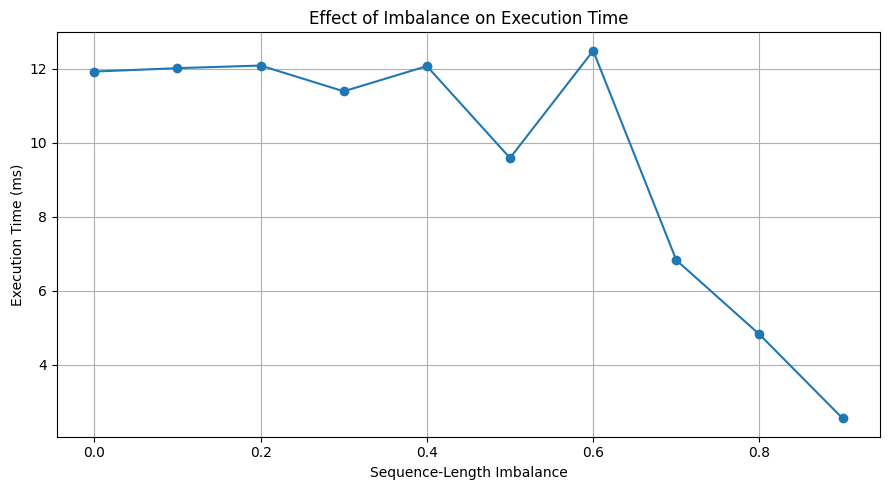


PHASE II SUMMARY


,Mean_Time,Mean_Comparisons,Mean_DP_Cells,Mean_LCS_Length
Group,,,,
Equal,14.6059,64375.0,64786.0,130.9
Fixed Total,9.5781,44687.5,45188.5,111.3
Unequal,11.5568,54750.0,55156.0,123.1



Phase II completed.
Results saved as LCS_Phase2_Results.csv


In [ ]:

import random
import time
import statistics
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# 1. EXPERIMENT SETTINGS
# ==================================================

rng = random.Random(528)
alphabet = "abcd"
repetitions = 5
results = []

# ==================================================
# 2. BOTTOM-UP DYNAMIC PROGRAMMING LCS
# ==================================================

def dynamic_lcs(X, Y):
    m = len(X)
    n = len(Y)

    dp = [[0] * (n + 1) for _ in range(m + 1)]
    comparisons = 0

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            comparisons += 1

            if X[i - 1] == Y[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(
                    dp[i - 1][j],
                    dp[i][j - 1]
                )

    return dp[m][n], comparisons


# ==================================================
# 3. GENERATE RANDOM STRINGS
# ==================================================

def make_string(length):
    return "".join(rng.choices(alphabet, k=length))


# ==================================================
# 4. EXPERIMENTAL INPUT LENGTHS
# ==================================================

equal_pairs = [
    (25, 25), (50, 50), (75, 75),
    (100, 100), (150, 150), (200, 200),
    (250, 250), (300, 300),
    (400, 400), (500, 500)
]

unequal_pairs = [
    (25, 50), (50, 75), (75, 100),
    (100, 150), (125, 200), (150, 250),
    (200, 300), (250, 350),
    (300, 450), (350, 500)
]

# All pairs have m + n = 500
fixed_pairs = [
    (250, 250), (225, 275), (200, 300),
    (175, 325), (150, 350), (125, 375),
    (100, 400), (75, 425),
    (50, 450), (25, 475)
]


# ==================================================
# 5. RUN ALL EXPERIMENTS
# ==================================================

for group, pairs in [
    ("Equal", equal_pairs),
    ("Unequal", unequal_pairs),
    ("Fixed Total", fixed_pairs)
]:

    for experiment, (m, n) in enumerate(pairs, 1):

        X = make_string(m)
        Y = make_string(n)

        times = []

        for _ in range(repetitions):
            start = time.perf_counter_ns()

            lcs_length, comparisons = dynamic_lcs(X, Y)

            elapsed_ms = (
                time.perf_counter_ns() - start
            ) / 1_000_000

            times.append(elapsed_ms)

        results.append({
            "Group": group,
            "Experiment": experiment,
            "m": m,
            "n": n,
            "Total Length": m + n,
            "LCS Length": lcs_length,
            "Comparisons": comparisons,
            "DP Cells": (m + 1) * (n + 1),
            "Imbalance": abs(m - n) / (m + n),
            "Time (ms)": statistics.median(times)
        })


# ==================================================
# 6. DISPLAY RESULTS
# ==================================================

df = pd.DataFrame(results)

print("PHASE II: LCS EXPERIMENTAL RESULTS")
display(df.round({
    "Imbalance": 3,
    "Time (ms)": 5
}))

df.to_csv("LCS_Phase2_Results.csv", index=False)


# ==================================================
# 7. SEPARATE EXPERIMENTAL GROUPS
# ==================================================

equal = df[df["Group"] == "Equal"]
unequal = df[df["Group"] == "Unequal"]
fixed = df[df["Group"] == "Fixed Total"]

# ==================================================
# GRAPH 1: EXECUTION TIME
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["Experiment"],
    equal["Time (ms)"],
    marker="o",
    label="Equal Lengths"
)

plt.plot(
    unequal["Experiment"],
    unequal["Time (ms)"],
    marker="s",
    label="Unequal Lengths"
)

plt.xlabel("Experiment Number")
plt.ylabel("Execution Time (ms)")
plt.title("LCS: Execution Time for Long Sequences")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 2: CHARACTER COMPARISONS
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["Experiment"],
    equal["Comparisons"],
    marker="o",
    label="Equal Lengths"
)

plt.plot(
    unequal["Experiment"],
    unequal["Comparisons"],
    marker="s",
    label="Unequal Lengths"
)

plt.xlabel("Experiment Number")
plt.ylabel("Character Comparisons")
plt.title("LCS: Comparisons for Long Sequences")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 3: DP TABLE SIZE
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    equal["Experiment"],
    equal["DP Cells"],
    marker="o",
    label="Equal Lengths"
)

plt.plot(
    unequal["Experiment"],
    unequal["DP Cells"],
    marker="s",
    label="Unequal Lengths"
)

plt.xlabel("Experiment Number")
plt.ylabel("DP Table Cells")
plt.title("LCS: Memory Requirements")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 4: TIME VS COMPARISONS
# ==================================================

plt.figure(figsize=(9, 5))

plt.scatter(
    equal["Comparisons"],
    equal["Time (ms)"],
    label="Equal Lengths",
    s=65
)

plt.scatter(
    unequal["Comparisons"],
    unequal["Time (ms)"],
    label="Unequal Lengths",
    s=65
)

plt.xlabel("Character Comparisons")
plt.ylabel("Execution Time (ms)")
plt.title("LCS: Execution Time vs Comparisons")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 5: EFFECT OF LENGTH IMBALANCE
# ==================================================

fixed = fixed.sort_values("Imbalance")

plt.figure(figsize=(9, 5))

plt.plot(
    fixed["Imbalance"],
    fixed["Comparisons"],
    marker="o"
)

plt.xlabel("Sequence-Length Imbalance")
plt.ylabel("Character Comparisons")
plt.title("Effect of Imbalance (m + n = 500)")
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# GRAPH 6: IMBALANCE VS EXECUTION TIME
# ==================================================

plt.figure(figsize=(9, 5))

plt.plot(
    fixed["Imbalance"],
    fixed["Time (ms)"],
    marker="o"
)

plt.xlabel("Sequence-Length Imbalance")
plt.ylabel("Execution Time (ms)")
plt.title("Effect of Imbalance on Execution Time")
plt.grid(True)
plt.tight_layout()
plt.show()


# ==================================================
# 8. SUMMARY STATISTICS
# ==================================================

print("\nPHASE II SUMMARY")

summary = df.groupby("Group").agg(
    Mean_Time=("Time (ms)", "mean"),
    Mean_Comparisons=("Comparisons", "mean"),
    Mean_DP_Cells=("DP Cells", "mean"),
    Mean_LCS_Length=("LCS Length", "mean")
)

display(summary.round(4))

print("\nPhase II completed.")
print("Results saved as LCS_Phase2_Results.csv")
